## Examen Final 
#### Nicolás M. Crespo - 544177
### Caso 1

In [2]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/Housing.csv')
df.info()
print(df.select_dtypes('number').shape[1], df.select_dtypes('object').shape[1])  # 6 7

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB
6 7


/tmp/ipykernel_2256/572208886.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes('number').shape[1], df.select_dtypes('object').shape[1])  # 6 7


In [3]:

from sklearn.model_selection import train_test_split

df = pd.read_csv('https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/Housing.csv')


binarias = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binarias:
    df[col] = df[col].map({'yes': 1, 'no': 0})


df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True, dtype=int)

X = df.drop(columns='price')
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(436, 13)
(109, 13)
(436,)
(109,)


In [5]:
from sklearn.metrics import r2_score, mean_absolute_error
print('R²:', round(r2_score(y_test, y_pred_lr), 4))
print('MAE:', round(mean_absolute_error(y_test, y_pred_lr), 3))

R²: 0.6529
MAE: 970043.404


In [6]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/Housing.csv')

binarias = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binarias:
    df[col] = df[col].map({'yes': 1, 'no': 0})

df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True, dtype=int)

X = df.drop(columns='price')
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

arbol = DecisionTreeRegressor(random_state=42)
arbol.fit(X_train, y_train)
y_pred_arbol = arbol.predict(X_test)

rmse_arbol = np.sqrt(mean_squared_error(y_test, y_pred_arbol))
print(f'RMSE_test Árbol: {rmse_arbol:.2f}')
print(f'R²_test Árbol: {r2_score(y_test, y_pred_arbol):.4f}')
print(f'MAE_test Árbol: {mean_absolute_error(y_test, y_pred_arbol):.2f}')

RMSE_test Árbol: 1625669.90
R²_test Árbol: 0.4771
MAE_test Árbol: 1195266.06


### Caso 2

In [7]:
df_credit = pd.read_csv(
    'https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/UCI_Credit_Card.csv',
    index_col='ID'
)

df_credit = df_credit.rename(columns={'default.payment.next.month': 'IsDefaulter'})

print(df_credit['IsDefaulter'].value_counts())

IsDefaulter
0    23364
1     6636
Name: count, dtype: int64


In [8]:
df_credit['EDUCATION'] = df_credit['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

print(df_credit['EDUCATION'].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64


In [9]:
df_credit['MARRIAGE'] = df_credit['MARRIAGE'].replace({0: 3})

print(df_credit['MARRIAGE'].value_counts().sort_index())

MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [10]:
edad_prom = df_credit.loc[df_credit['IsDefaulter'] == 1, 'AGE'].mean()
print(round(edad_prom, 2))

35.73


In [11]:
df_credit = pd.get_dummies(df_credit, columns=['EDUCATION', 'MARRIAGE'], dtype=int)

print([c for c in df_credit.columns if c.startswith(('EDUCATION_', 'MARRIAGE_'))])
print(df_credit.shape)

['EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']
(30000, 29)


In [12]:
cols_pay = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

print(df_credit[cols_pay].nunique())

df_credit = pd.get_dummies(df_credit, columns=cols_pay, drop_first=True, dtype=int)

print(len([c for c in df_credit.columns if c.startswith('PAY_') and not c.startswith('PAY_AMT')]))
print(df_credit.shape)

PAY_0    11
PAY_2    11
PAY_3    11
PAY_4    11
PAY_5    10
PAY_6    10
dtype: int64
58
(30000, 81)


In [13]:
df_credit = df_credit.drop(columns='ID', errors='ignore')
print(df_credit.shape)  

(30000, 81)


In [14]:
from sklearn.model_selection import train_test_split

X_c = df_credit.drop(columns='IsDefaulter')
y_c = df_credit['IsDefaulter']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c, test_size=0.33, random_state=42, stratify=df_credit.IsDefaulter
)

print(len(X_train_c))   
print(len(X_test_c))    

20100
9900


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

scaler_c = StandardScaler().fit(X_train_c)
X_train_c_s = pd.DataFrame(scaler_c.transform(X_train_c), columns=X_train_c.columns, index=X_train_c.index)
X_test_c_s = pd.DataFrame(scaler_c.transform(X_test_c), columns=X_test_c.columns, index=X_test_c.index)

log_reg = LogisticRegression(C=10, penalty='l2', random_state=42,
                             class_weight='balanced', max_iter=2000)
log_reg.fit(X_train_c_s, y_train_c)

y_pred_log = log_reg.predict(X_test_c_s)

print('Accuracy test:', round(accuracy_score(y_test_c, y_pred_log), 2))
print('Precisión:', round(precision_score(y_test_c, y_pred_log), 4))
print('Recall:', round(recall_score(y_test_c, y_pred_log), 4))
print('F1:', round(f1_score(y_test_c, y_pred_log), 4))

/workspaces/aprendizaje-no-supervisado-544177/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Accuracy test: 0.78
Precisión: 0.4932
Recall: 0.5658
F1: 0.527


[[6437 1273]
 [ 951 1239]]


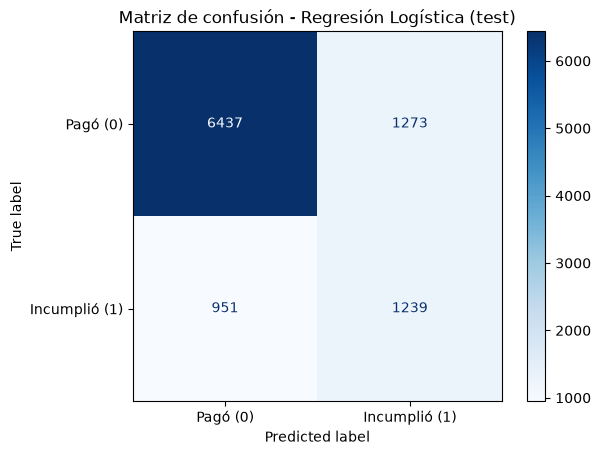

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_c, y_pred_log, labels=[0, 1])
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Pagó (0)', 'Incumplió (1)'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Regresión Logística (test)')
plt.show()

In [19]:
from sklearn.tree import DecisionTreeClassifier

arbol_c = DecisionTreeClassifier(max_depth=20, min_samples_split=0.1,
                                 random_state=42, class_weight='balanced')
arbol_c.fit(X_train_c, y_train_c)          # datos SIN escalar

y_pred_arbol_c = arbol_c.predict(X_test_c)

print('Accuracy test:', round(accuracy_score(y_test_c, y_pred_arbol_c), 2))
print('Precisión:', round(precision_score(y_test_c, y_pred_arbol_c), 4))
print('Recall:', round(recall_score(y_test_c, y_pred_arbol_c), 4))
print('F1:', round(f1_score(y_test_c, y_pred_arbol_c), 4))

Accuracy test: 0.71
Precisión: 0.4103
Recall: 0.6648
F1: 0.5074


In [20]:
comparacion = pd.DataFrame([
    {'modelo': 'Regresión Logística',
     'accuracy': accuracy_score(y_test_c, y_pred_log),
     'precisión': precision_score(y_test_c, y_pred_log),
     'recall': recall_score(y_test_c, y_pred_log),
     'F1': f1_score(y_test_c, y_pred_log)},
    {'modelo': 'Decision Tree',
     'accuracy': accuracy_score(y_test_c, y_pred_arbol_c),
     'precisión': precision_score(y_test_c, y_pred_arbol_c),
     'recall': recall_score(y_test_c, y_pred_arbol_c),
     'F1': f1_score(y_test_c, y_pred_arbol_c)},
]).round(4)

print(comparacion)

                modelo  accuracy  precisión  recall      F1
0  Regresión Logística    0.7754     0.4932  0.5658  0.5270
1        Decision Tree    0.7144     0.4103  0.6648  0.5074


### Caso 3

In [21]:
df_college = pd.read_csv('https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/College_Data.csv')
df_college = df_college.drop(columns='College', errors='ignore')

df_college.info()
df_college.head()

<class 'pandas.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Private      777 non-null    str    
 1   Apps         777 non-null    int64  
 2   Accept       777 non-null    int64  
 3   Enroll       777 non-null    int64  
 4   Top10perc    777 non-null    int64  
 5   Top25perc    777 non-null    int64  
 6   F.Undergrad  777 non-null    int64  
 7   P.Undergrad  777 non-null    int64  
 8   Outstate     777 non-null    int64  
 9   Room.Board   777 non-null    int64  
 10  Books        777 non-null    int64  
 11  Personal     777 non-null    int64  
 12  PhD          777 non-null    int64  
 13  Terminal     777 non-null    int64  
 14  S.F.Ratio    777 non-null    float64
 15  perc.alumni  777 non-null    int64  
 16  Expend       777 non-null    int64  
 17  Grad.Rate    777 non-null    int64  
dtypes: float64(1), int64(16), str(1)
memory usage: 109.4 KB


,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_col = df_college.copy()
if 'Private' in X_col.columns:
    X_col['Private'] = X_col['Private'].map({'Yes': 1, 'No': 0})

km2 = KMeans(n_clusters=2, random_state=42, n_init='auto').fit(X_col)   # SIN escalar
sil = silhouette_score(X_col, km2.labels_)
print('Silhouette K=2 sin escalar:', round(sil, 2))

Silhouette K=2 sin escalar: 0.54


In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

X_col_s = StandardScaler().fit_transform(X_col)

db = DBSCAN(eps=2.0, min_samples=5).fit(X_col_s)
labels_db = db.labels_

n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print('Clusters (sin ruido):', n_clusters)
print('Puntos de ruido:', (labels_db == -1).sum(), f'({100 * (labels_db == -1).mean():.1f}%)')
print(pd.Series(labels_db).value_counts().sort_index())

Clusters (sin ruido): 3
Puntos de ruido: 289 (37.2%)
-1    289
 0    416
 1      8
 2     64
Name: count, dtype: int64


In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.8, random_state=42)
X_pca = pca.fit_transform(X_col_s)

print('Componentes retenidos:', pca.n_components_)
print('Varianza explicada acumulada:', round(pca.explained_variance_ratio_.sum(), 4))

km3 = KMeans(n_clusters=3, random_state=42, n_init='auto').fit(X_pca)
sil_pca = silhouette_score(X_pca, km3.labels_)
print('Silhouette K=3 sobre PCA:', round(sil_pca, 2))

Componentes retenidos: 6
Varianza explicada acumulada: 0.8081
Silhouette K=3 sobre PCA: 0.29
